# Food.com recipe recommendation for new and rarely reviewed recipes: data preprocessing

This notebook prepares the Food.com data (Majumder et al., EMNLP 2019) for an **implicit-feedback recommendation** task:
given a user's review history, rank recipes they are likely to review next, with a focus on recipes that have
**few or no** past reviews (item cold start).

**Outputs** (written to `processed/`):

| File | Contents |
|---|---|
| `train.csv`, `valid.csv`, `test.csv` | time-based splits with integer user index `u`, recipe index `i`, and cold-start bucket |
| `recipes.csv` | recipe catalog: `recipe_id`, index `i`, submission date, name |
| `X_ingr.npz`, `X_tags.npz`, `X_num.npy` | recipe content features (ingredient TF-IDF, tag multi-hot, numeric) |
| `neg_valid.npy`, `neg_test.npy` | 100 fixed sampled negatives per evaluation row, so every model is evaluated on the same candidates |
| `feature_names.json`, `config.json` | feature vocabularies and the settings used |

**Split design:**
- Train: interactions before 2015-01-01; validation: 2015; test: 2016 onward.
- Users are filtered by activity **in the training period only**, so the filter never looks at the future.
- Validation is for tuning hyperparameters; for the final test, models are retrained on train + validation.

In [1]:
import ast, json, os
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

DATA_DIR = "dataset"
OUT_DIR = "processed"
os.makedirs(OUT_DIR, exist_ok=True)

CONFIG = {
    "min_user_train_interactions": 5,   # keep users with >= this many training-period reviews
    "valid_start": "2015-01-01",
    "test_start": "2016-01-01",
    "n_negatives": 100,                 # sampled negatives per evaluation row
    "ingr_min_df": 5,                   # ingredient must appear in >= 5 recipes
    "tag_min_df": 20,                   # tag must appear in >= 20 recipes
    "tag_max_df": 0.5,                  # drop near-universal tags like 'time-to-make'
    "seed": 0,
}
rng = np.random.default_rng(CONFIG["seed"])
pd.set_option("display.width", 120)

## 1. Load raw data

In [2]:
inter = pd.read_csv(f"{DATA_DIR}/RAW_interactions.csv", parse_dates=["date"])
recipes = pd.read_csv(f"{DATA_DIR}/RAW_recipes.csv", parse_dates=["submitted"])

print(f"interactions: {len(inter):,}   users: {inter.user_id.nunique():,}   recipes reviewed: {inter.recipe_id.nunique():,}")
print(f"recipe catalog: {len(recipes):,}")
inter.head()

interactions: 1,132,367   users: 226,570   recipes reviewed: 231,637
recipe catalog: 231,637


,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


In [3]:
recipes.head(2)

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6


## 2. Exploratory statistics

These numbers motivate the task framing:
- **Ratings are mostly 5 stars**, so predicting the star value carries little signal. We treat every review as a positive (implicit) interaction.
- **Rating 0 means "reviewed without a rating"**, not one star. It still counts as an interaction.
- **Reviews per recipe and per user are long-tailed.** Most recipes have very few reviews, which is the cold-start problem.

In [4]:
r = inter.rating
rated = r[r > 0]
print(f"mean rating (excluding 0 = no rating): {rated.mean():.3f}   median: {rated.median():.0f}   std: {rated.std():.3f}")
print("\nrating distribution (share of all reviews):")
print(r.value_counts(normalize=True).sort_index().round(3).to_string())

per_recipe = inter.groupby("recipe_id").size()
per_user = inter.groupby("user_id").size()
print(f"\nreviews per recipe: median {per_recipe.median():.0f}, mean {per_recipe.mean():.2f}, max {per_recipe.max()}")
for k in [1, 5, 10]:
    print(f"  recipes with <= {k:>2} reviews: {(per_recipe <= k).mean():.1%}")
print(f"\nreviews per user: median {per_user.median():.0f}, mean {per_user.mean():.2f}, max {per_user.max()}")
for k in [1, 5, 10]:
    print(f"  users with >= {k:>2} reviews: {(per_user >= k).sum():,} ({(per_user >= k).mean():.1%}), "
          f"covering {per_user[per_user >= k].sum() / len(inter):.1%} of interactions")

mean rating (excluding 0 = no rating): 4.661   median: 5   std: 0.723

rating distribution (share of all reviews):
rating
0    0.054
1    0.011
2    0.012
3    0.036
4    0.165
5    0.721

reviews per recipe: median 2, mean 4.89, max 1613
  recipes with <=  1 reviews: 39.7%
  recipes with <=  5 reviews: 81.5%
  recipes with <= 10 reviews: 91.9%

reviews per user: median 1, mean 5.00, max 7671
  users with >=  1 reviews: 226,570 (100.0%), covering 100.0% of interactions
  users with >=  5 reviews: 23,086 (10.2%), covering 77.0% of interactions
  users with >= 10 reviews: 12,486 (5.5%), covering 70.9% of interactions


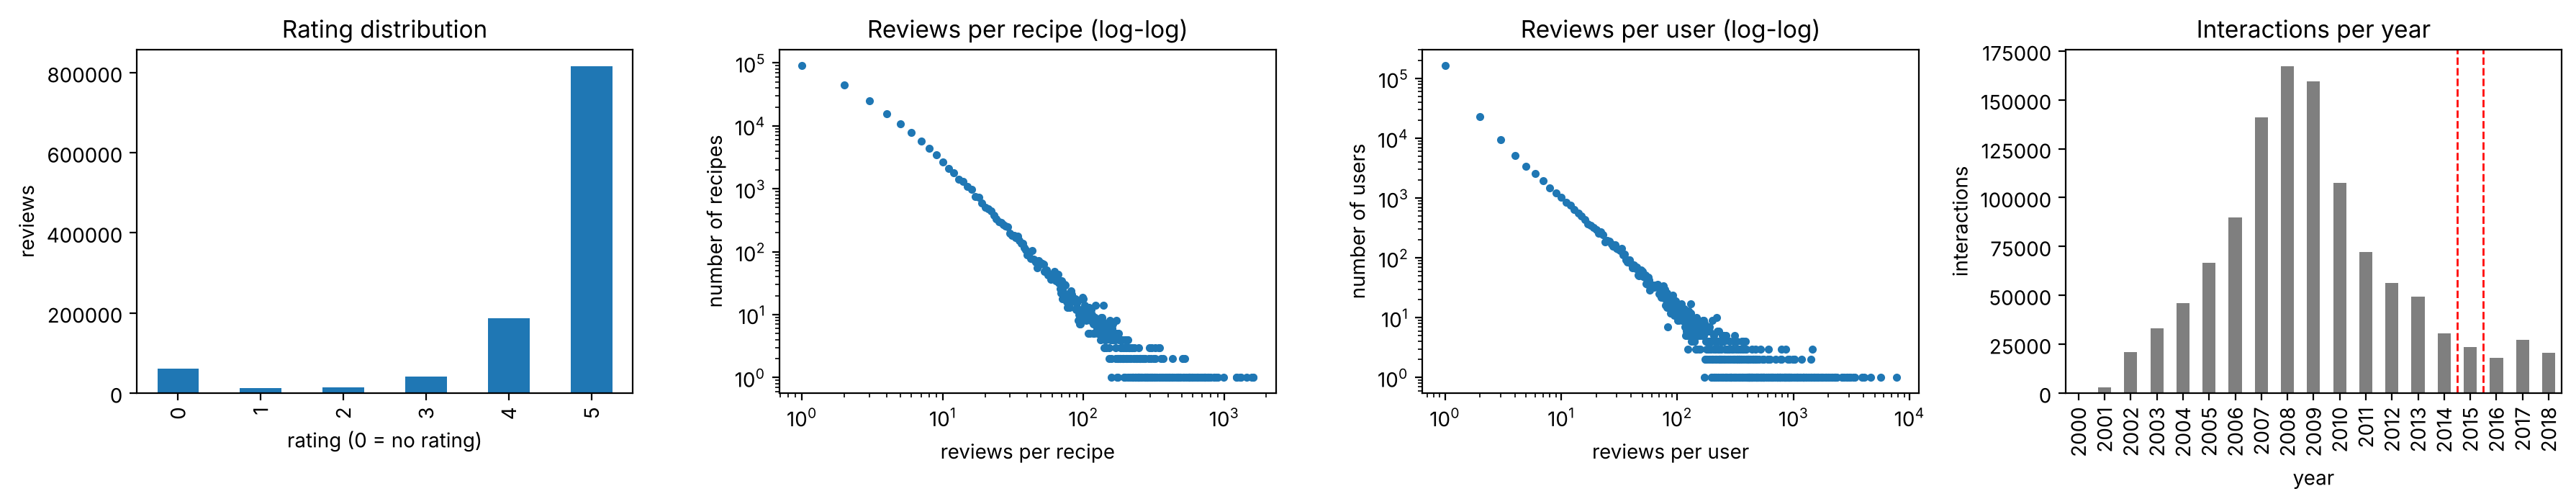

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))

inter.rating.value_counts().sort_index().plot.bar(ax=axes[0], color="tab:blue")
axes[0].set(title="Rating distribution", xlabel="rating (0 = no rating)", ylabel="reviews")

for ax, counts, name in [(axes[1], per_recipe, "recipe"), (axes[2], per_user, "user")]:
    vc = counts.value_counts().sort_index()
    ax.loglog(vc.index, vc.values, "o", ms=3)
    ax.set(title=f"Reviews per {name} (log-log)", xlabel=f"reviews per {name}", ylabel=f"number of {name}s")

inter.date.dt.year.value_counts().sort_index().plot.bar(ax=axes[3], color="tab:gray")
axes[3].set(title="Interactions per year", xlabel="year", ylabel="interactions")
for x in (15, 16):  # bar positions of 2015 and 2016
    axes[3].axvline(x - 0.5, color="red", ls="--", lw=1)
plt.tight_layout(); plt.show()

## 3. Clean interactions

In [6]:
n0 = len(inter)
inter = inter.dropna(subset=["user_id", "recipe_id", "date"])
# keep only recipes that exist in the catalog (needed for content features)
inter = inter[inter.recipe_id.isin(recipes.id)]
# a user reviewing the same recipe twice counts as one interaction: keep the earliest
inter = inter.sort_values("date").drop_duplicates(["user_id", "recipe_id"], keep="first")
print(f"removed {n0 - len(inter):,} rows (missing values, unknown recipes, duplicates); {len(inter):,} remain")

removed 0 rows (missing values, unknown recipes, duplicates); 1,132,367 remain


## 4. Clean the recipe catalog

- Parse the list-valued columns (`tags`, `ingredients`, `nutrition`).
- Split `nutrition` into named columns (calories, then % daily value for fat, sugar, sodium, protein, saturated fat, carbohydrates).
- `minutes` has absurd outliers (some recipes list months), so we clip at the 99.9th percentile before taking logs.
- Recipe content is known when the recipe is published, so fitting feature transforms on the whole catalog does not leak any interaction labels.

In [7]:
recipes = recipes.rename(columns={"id": "recipe_id"})
for col in ["tags", "ingredients", "nutrition"]:
    recipes[col] = recipes[col].apply(ast.literal_eval)

nut_cols = ["calories", "total_fat_pdv", "sugar_pdv", "sodium_pdv", "protein_pdv", "sat_fat_pdv", "carbs_pdv"]
recipes[nut_cols] = pd.DataFrame(recipes.nutrition.tolist(), index=recipes.index)

# normalize ingredient strings
recipes["ingredients"] = recipes.ingredients.apply(lambda xs: [x.strip().lower() for x in xs])

print("minutes percentiles:", recipes.minutes.quantile([.5, .9, .99, .999, 1]).to_dict())
print("missing submission dates:", recipes.submitted.isna().sum())
recipes[["recipe_id", "minutes", "n_steps", "n_ingredients"] + nut_cols].describe().round(1)

minutes percentiles: {0.5: 40.0, 0.9: 135.0, 0.99: 903.9199999999546, 0.999: 10095.0, 1.0: 2147483647.0}
missing submission dates: 0


,recipe_id,minutes,n_steps,n_ingredients,calories,total_fat_pdv,sugar_pdv,sodium_pdv,protein_pdv,sat_fat_pdv,carbs_pdv
count,231637.0,2.316370e+05,231637.0,231637.0,231637.0,231637.0,231637.0,231637.0,231637.0,231637.0,231637.0
mean,222014.7,9.398500e+03,9.8,9.1,473.9,36.1,84.3,30.1,34.7,45.6,15.6
std,141206.6,4.461963e+06,6.0,3.7,1189.7,77.8,800.1,132.0,58.5,98.2,81.8
min,38.0,0.000000e+00,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,99944.0,2.000000e+01,6.0,6.0,174.4,8.0,9.0,5.0,7.0,7.0,4.0
50%,207249.0,4.000000e+01,9.0,9.0,313.4,20.0,25.0,14.0,18.0,23.0,9.0
75%,333816.0,6.500000e+01,12.0,11.0,519.7,41.0,68.0,33.0,51.0,52.0,16.0
max,537716.0,2.147484e+09,145.0,43.0,434360.2,17183.0,362729.0,29338.0,6552.0,10395.0,36098.0


## 5. Time-based split and user filtering

We split by time rather than at random. That mirrors deployment: the model is trained on the past and asked about the future,
and recipes published after the cutoff naturally show up as **new recipes** with no training reviews.

Users need at least `min_user_train_interactions` reviews **before the validation start date**. Validation and test rows
are kept only for these users, because a pure collaborative model has nothing to say about users it never saw.

In [8]:
valid_start, test_start = pd.Timestamp(CONFIG["valid_start"]), pd.Timestamp(CONFIG["test_start"])

train_period = inter[inter.date < valid_start]
user_train_counts = train_period.groupby("user_id").size()
keep_users = user_train_counts[user_train_counts >= CONFIG["min_user_train_interactions"]].index

inter_f = inter[inter.user_id.isin(keep_users)]
train = inter_f[inter_f.date < valid_start].copy()
valid = inter_f[(inter_f.date >= valid_start) & (inter_f.date < test_start)].copy()
test = inter_f[inter_f.date >= test_start].copy()

n_items_seen = train.recipe_id.nunique()
print(f"kept users: {len(keep_users):,}")
print(f"train: {len(train):,}   valid: {len(valid):,}   test: {len(test):,}")
print(f"train density: {len(train) / (len(keep_users) * n_items_seen):.2e}")
print(f"valid users: {valid.user_id.nunique():,}   test users: {test.user_id.nunique():,}")

kept users: 22,246
train: 850,011   valid: 5,967   test: 8,759
train density: 1.83e-04
valid users: 1,457   test users: 1,647


## 6. Integer indices

- `u`: users, indexed over the training users.
- `i`: recipes, indexed over the **entire catalog**, so recipes with zero training reviews still have an index (and content features).

In [9]:
user_ids = np.sort(keep_users.values)
user2u = {uid: k for k, uid in enumerate(user_ids)}

recipes = recipes.sort_values("recipe_id").reset_index(drop=True)
recipes["i"] = np.arange(len(recipes))
recipe2i = dict(zip(recipes.recipe_id, recipes.i))

for df in (train, valid, test):
    df["u"] = df.user_id.map(user2u).astype(int)
    df["i"] = df.recipe_id.map(recipe2i).astype(int)
print(f"{len(user_ids):,} users x {len(recipes):,} recipes")

22,246 users x 231,637 recipes


## 7. Cold-start buckets

Each evaluation row is labeled by how many reviews its recipe had in the data the model is trained on:
- validation rows: counted on `train`
- test rows: counted on `train + valid` (the final model is retrained on both)

Buckets: `0` (new), `1-5` (rare), `>5` (well-reviewed).

        valid  test
bucket             
0         654  1162
1-5      2061  2854
>5       3252  4743


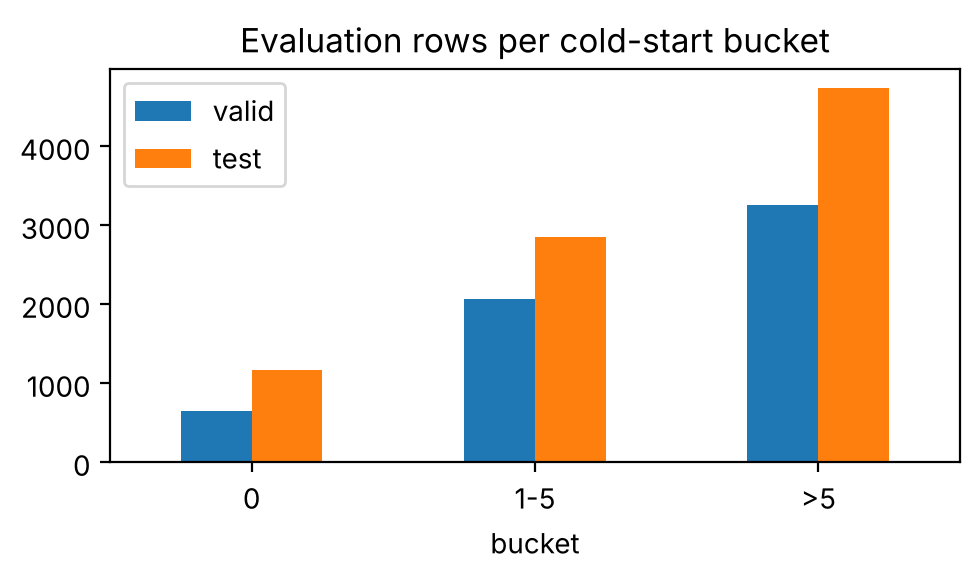

In [10]:
def add_buckets(eval_df, fit_df):
    counts = fit_df.groupby("i").size()
    n = eval_df.i.map(counts).fillna(0).astype(int)
    eval_df["n_train"] = n
    eval_df["bucket"] = pd.cut(n, bins=[-1, 0, 5, np.inf], labels=["0", "1-5", ">5"]).astype(str)
    return eval_df

valid = add_buckets(valid, train)
test = add_buckets(test, pd.concat([train, valid]))

summary = pd.DataFrame({
    "valid": valid.bucket.value_counts(),
    "test": test.bucket.value_counts(),
}).loc[["0", "1-5", ">5"]]
print(summary)
summary.plot.bar(figsize=(5, 3), title="Evaluation rows per cold-start bucket", rot=0); plt.tight_layout(); plt.show()

## 8. Recipe content features

Three blocks, saved separately so models can weight or combine them:

1. **Ingredients:** TF-IDF where each whole ingredient string is one token, so "olive oil" is one feature rather than "olive" + "oil".
2. **Tags:** binary indicators. Very rare tags (< `tag_min_df` recipes) and near-universal ones (> `tag_max_df` of recipes, e.g. `time-to-make`) are dropped.
3. **Numeric:** log(minutes), number of steps, number of ingredients and the 7 nutrition values, log-transformed and standardized.

In [11]:
ingr_vec = TfidfVectorizer(analyzer=lambda xs: xs, min_df=CONFIG["ingr_min_df"])
X_ingr = ingr_vec.fit_transform(recipes.ingredients).tocsr().astype(np.float32)

tag_vec = CountVectorizer(analyzer=lambda xs: xs, binary=True,
                          min_df=CONFIG["tag_min_df"], max_df=CONFIG["tag_max_df"])
X_tags = tag_vec.fit_transform(recipes.tags).tocsr().astype(np.float32)

num = pd.DataFrame({
    "log_minutes": np.log1p(recipes.minutes.clip(upper=recipes.minutes.quantile(0.999))),
    "n_steps": np.log1p(recipes.n_steps),
    "n_ingredients": np.log1p(recipes.n_ingredients),
})
for c in nut_cols:
    num[c] = np.log1p(recipes[c].clip(lower=0))
X_num = ((num - num.mean()) / num.std()).fillna(0).values.astype(np.float32)

print(f"ingredient TF-IDF: {X_ingr.shape}, nnz/recipe = {X_ingr.nnz / X_ingr.shape[0]:.1f}")
print(f"tags:              {X_tags.shape}, nnz/recipe = {X_tags.nnz / X_tags.shape[0]:.1f}")
print(f"numeric:           {X_num.shape}")

ingredient TF-IDF: (231637, 8010), nnz/recipe = 9.0
tags:              (231637, 468), nnz/recipe = 13.0
numeric:           (231637, 10)


In [12]:
# sanity check: most common ingredients and tags
ingr_df = pd.Series(np.asarray((X_ingr > 0).sum(0)).ravel(), index=ingr_vec.get_feature_names_out())
tag_df = pd.Series(np.asarray(X_tags.sum(0)).ravel(), index=tag_vec.get_feature_names_out())
print("top ingredients:", ", ".join(ingr_df.nlargest(15).index))
print("top tags kept:  ", ", ".join(tag_df.nlargest(15).index))

top ingredients: salt, butter, sugar, onion, water, eggs, olive oil, flour, milk, garlic cloves, pepper, brown sugar, garlic, all-purpose flour, baking powder
top tags kept:   occasion, cuisine, low-in-something, main-dish, equipment, 60-minutes-or-less, number-of-servings, meat, 30-minutes-or-less, vegetables, taste-mood, 4-hours-or-less, north-american, 3-steps-or-less, 15-minutes-or-less


## 9. Fixed negative samples for evaluation

For each validation and test row we sample `n_negatives` recipes the user never reviewed. The true recipe is then ranked against
them (AUC, Hit@10). Saving the samples means **every model is scored on exactly the same candidates**.

To stay realistic, negatives are drawn only from recipes **already published on the interaction date**: a recipe that did not exist
yet could not have been recommended.

Note: ranking against 100 sampled negatives inflates absolute numbers compared with ranking the full catalog. That's fine for
comparing models with each other, but it should be mentioned when reporting.

In [13]:
# catalog ordered by submission date, so "published by date d" is a prefix of this array
order = np.argsort(recipes.submitted.values, kind="stable")
sub_sorted = recipes.submitted.values[order]
items_by_date = recipes.i.values[order]

user_pos = defaultdict(set)
for df in (train, valid, test):
    for u, i in zip(df.u.values, df.i.values):
        user_pos[u].add(i)

def sample_negatives(eval_df, n_neg):
    out = np.empty((len(eval_df), n_neg), dtype=np.int64)
    limits = np.searchsorted(sub_sorted, eval_df.date.values, side="right")
    for row, (u, lim) in enumerate(zip(eval_df.u.values, limits)):
        seen, negs = user_pos[u], []
        while len(negs) < n_neg:
            cand = items_by_date[rng.integers(0, lim, size=2 * n_neg)]
            negs.extend(c for c in cand if c not in seen and c not in negs)
        out[row] = negs[:n_neg]
    return out

# a recipe must not be reviewed before it was published; drop the rare rows where dates disagree
pub = recipes.set_index("i").submitted
for name, df in [("valid", valid), ("test", test)]:
    bad = (df.date < df.i.map(pub)).sum()
    print(f"{name}: {bad} rows reviewed before their recipe's submission date (dropped)")
valid = valid[valid.date >= valid.i.map(pub)].reset_index(drop=True)
test = test[test.date >= test.i.map(pub)].reset_index(drop=True)

neg_valid = sample_negatives(valid, CONFIG["n_negatives"])
neg_test = sample_negatives(test, CONFIG["n_negatives"])
print(neg_valid.shape, neg_test.shape)

valid: 0 rows reviewed before their recipe's submission date (dropped)
test: 0 rows reviewed before their recipe's submission date (dropped)


(5967, 100) (8759, 100)


## 10. Save

In [14]:
cols = ["user_id", "recipe_id", "u", "i", "date", "rating"]
train[cols].to_csv(f"{OUT_DIR}/train.csv", index=False)
valid[cols + ["n_train", "bucket"]].to_csv(f"{OUT_DIR}/valid.csv", index=False)
test[cols + ["n_train", "bucket"]].to_csv(f"{OUT_DIR}/test.csv", index=False)
recipes[["recipe_id", "i", "submitted", "name"]].to_csv(f"{OUT_DIR}/recipes.csv", index=False)

sp.save_npz(f"{OUT_DIR}/X_ingr.npz", X_ingr)
sp.save_npz(f"{OUT_DIR}/X_tags.npz", X_tags)
np.save(f"{OUT_DIR}/X_num.npy", X_num)
np.save(f"{OUT_DIR}/neg_valid.npy", neg_valid)
np.save(f"{OUT_DIR}/neg_test.npy", neg_test)

with open(f"{OUT_DIR}/feature_names.json", "w") as f:
    json.dump({"ingredients": ingr_vec.get_feature_names_out().tolist(),
               "tags": tag_vec.get_feature_names_out().tolist(),
               "numeric": num.columns.tolist()}, f)
with open(f"{OUT_DIR}/config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

for fn in sorted(os.listdir(OUT_DIR)):
    print(f"{fn:22s} {os.path.getsize(os.path.join(OUT_DIR, fn)) / 1e6:8.1f} MB")

X_ingr.npz                 11.1 MB
X_num.npy                   9.3 MB
X_tags.npz                  3.2 MB
config.json                 0.0 MB
feature_names.json          0.2 MB
neg_test.npy                7.0 MB
neg_valid.npy               4.8 MB
recipes.csv                12.3 MB
test.csv                    0.4 MB
train.csv                  32.2 MB
valid.csv                   0.3 MB


## 11. Summary

The final numbers to quote in the presentation.

The provided `interactions_*.csv` files (the paper's split) are a different, harder setting: every test recipe has **zero** training
interactions. They can serve as an extra pure-cold-start benchmark, but this project's main evaluation uses the time split above.

In [15]:
final = pd.DataFrame({
    "rows": [len(train), len(valid), len(test)],
    "users": [train.u.nunique(), valid.u.nunique(), test.u.nunique()],
    "recipes": [train.i.nunique(), valid.i.nunique(), test.i.nunique()],
    "date range": [f"{d.date.min():%Y-%m} to {d.date.max():%Y-%m}" for d in (train, valid, test)],
}, index=["train", "valid", "test"])
print(final.to_string())
print("\ntest rows by bucket:"); print(test.bucket.value_counts().loc[["0", "1-5", ">5"]].to_string())

         rows  users  recipes          date range
train  850011  22246   208822  2000-02 to 2014-12
valid    5967   1457     4942  2015-01 to 2015-12
test     8759   1647     6835  2016-01 to 2018-12

test rows by bucket:
bucket
0      1162
1-5    2854
>5     4743
